In [ ]:
import pandas as pd
import numpy as np


In [ ]:
df = pd.read_excel("Dataset.xlsx")

FileNotFoundError: [Errno 2] No such file or directory: 'Dataset.xlsx'

In [ ]:
df.head()

,CustomerID,Age,Annual _Income,City
0,101,23.0,50.0,New York
1,102,45.0,85.0,Paris
2,103,NaN,62.0,New York
3,104,31.0,NaN,London
4,105,22.0,45.0,NaN


In [ ]:
df.shape

(7, 4)

In [ ]:
df.replace("NaN",np.nan,inplace=True)

In [ ]:
df.isnull().sum()

,0
CustomerID,0
Age,1
Annual _Income,1
City,1


In [ ]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Annual _Income"] = df["Annual _Income"].fillna(df["Annual _Income"].median())
df["City"] = df["City"].fillna(df["City"].mode()[0])

In [ ]:
df.head()

,CustomerID,Age,Annual _Income,City
0,101,23.0,50.0,New York
1,102,45.0,85.0,Paris
2,103,34.5,62.0,New York
3,104,31.0,73.5,London
4,105,22.0,45.0,London


In [ ]:
Q1 = df["Annual _Income"].quantile(0.25)
Q3 = df["Annual _Income"].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
mean = df["Annual _Income"].mean()

df.loc[(df["Annual _Income"] < lower) | (df["Annual _Income"] > upper), "Annual _Income"] = mean

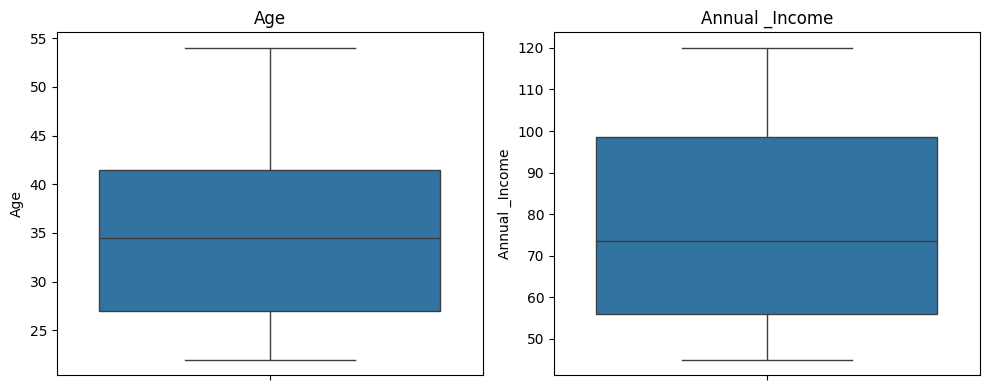

In [ ]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.boxplot(y=df["Age"])
plt.title("Age")

plt.subplot(1,2,2)
sns.boxplot(y=df["Annual _Income"])
plt.title("Annual _Income")

plt.tight_layout()
plt.show()


In [ ]:
df = df.drop('CustomerID ', axis=1)

In [ ]:
df.head()

,Age,Annual _Income,City
0,23.0,50.0,New York
1,45.0,85.0,Paris
2,34.5,62.0,New York
3,31.0,73.5,London
4,22.0,45.0,London


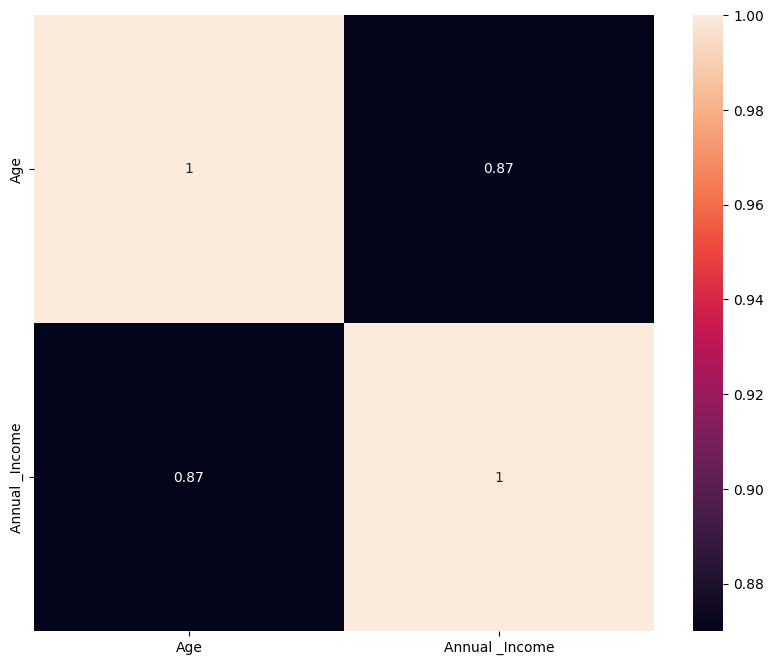

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()